In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Utility functions
from utils import evaluate_model, plot_confusion_matrix, plot_roc_curves, compare_models

sns.set_theme(style="whitegrid")
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("data/titanic_cleaned.csv")
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
0,0,3,0,22.0,1,0,7.2500,0,2,0,...,1,0,0,0,1,0,0,0,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,...,0,1,0,0,0,1,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,1,1,...,0,0,0,0,1,0,0,1,0,0
3,1,1,1,35.0,1,0,53.1000,1,2,0,...,0,1,0,0,1,0,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,1,1,...,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,0,1,1,...,0,0,1,0,1,0,0,1,0,0
887,1,1,1,19.0,0,0,30.0000,1,1,1,...,0,0,0,0,1,0,0,0,1,0
888,0,3,1,21.5,1,2,23.4500,0,4,0,...,0,0,0,0,1,0,0,0,1,0
889,1,1,0,26.0,0,0,30.0000,1,1,1,...,1,0,0,0,1,0,0,0,1,0


## Features and Target

In [4]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"\nFeature columns: {X.columns.tolist()}")


Features shape: (891, 22)
Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Feature columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeGroup_Teen', 'AgeGroup_Young Adult', 'AgeGroup_Adult', 'AgeGroup_Senior', 'FareBin_Medium', 'FareBin_High', 'FareBin_Very High']


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,# stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining survival rate: {y_train.mean():.2%}")
print(f"Test survival rate: {y_test.mean():.2%}")

Training set: 712 samples
Test set: 179 samples

Training survival rate: 38.76%
Test survival rate: 36.87%


In [9]:
# Feature scaling — for KNN, SVM, and Logistic Regression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Scaling complete. First 3 rows of scaled training data:")
X_train_scaled.head(3)

Scaling complete. First 3 rows of scaled training data:


,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_Q,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
60,0.837268,-0.749269,-0.535719,-0.484115,-0.486958,-0.502195,-0.555719,-0.577672,0.845968,-0.300586,...,0.863191,-0.415911,-0.174329,-0.292174,0.870646,-0.575188,-0.156398,-0.555719,-0.590326,-0.594653
557,-1.547272,-0.749269,0.823795,-0.484115,-0.486958,3.737503,-0.555719,-0.577672,0.845968,-0.300586,...,0.863191,-0.415911,-0.174329,-0.292174,-1.148572,1.738562,-0.156398,-0.555719,-0.590326,1.681653
137,-1.547272,-0.749269,0.597209,0.386314,-0.486958,0.380610,1.799471,0.016696,-1.182077,-0.300586,...,0.863191,-0.415911,-0.174329,-0.292174,-1.148572,1.738562,-0.156398,-0.555719,-0.590326,1.681653


# Model Training

In [10]:
# Store results for comparison
results = []
trained_models = {}

## Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression


  Logistic Regression Results
  Accuracy:  0.8101
  Precision: 0.7581
  Recall:    0.7121
  F1 Score:  0.7344

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85       113
           1       0.76      0.71      0.73        66

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



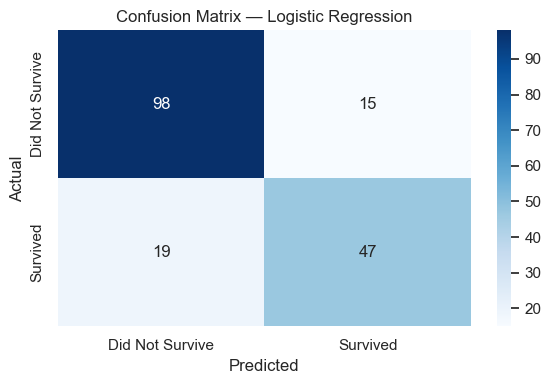

In [14]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
metrics_lr = evaluate_model(y_test, y_pred_lr, "Logistic Regression")
results.append(metrics_lr)
trained_models["Logistic Regression"] = lr

plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")


## Decision Tree


  Decision Tree Results
  Accuracy:  0.8101
  Precision: 0.7500
  Recall:    0.7273
  F1 Score:  0.7385

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       113
           1       0.75      0.73      0.74        66

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



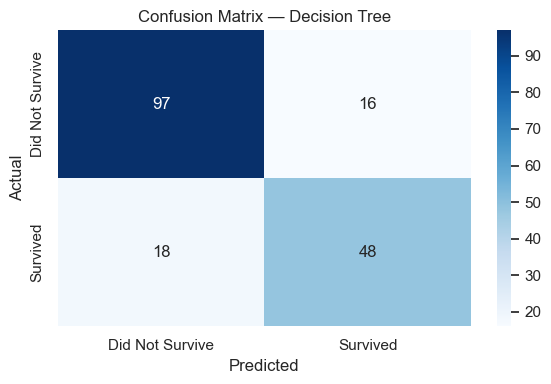

In [15]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
metrics_dt = evaluate_model(y_test, y_pred_dt, "Decision Tree")
results.append(metrics_dt)
trained_models["Decision Tree"] = dt

plot_confusion_matrix(y_test, y_pred_dt, "Decision Tree")


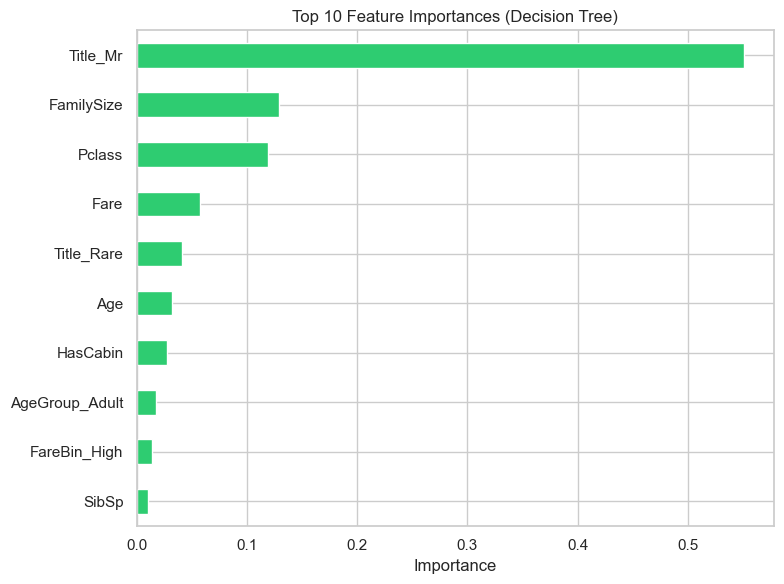

In [16]:
# Feature importance from Decision Tree
feature_imp = pd.Series(dt.feature_importances_, index=X_train.columns)
feature_imp = feature_imp.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp.tail(10).plot(kind="barh", ax=ax, color="#2ecc71")
ax.set_title("Top 10 Feature Importances (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## Random Forest


  Random Forest Results
  Accuracy:  0.8212
  Precision: 0.8036
  Recall:    0.6818
  F1 Score:  0.7377

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       113
           1       0.80      0.68      0.74        66

    accuracy                           0.82       179
   macro avg       0.82      0.79      0.80       179
weighted avg       0.82      0.82      0.82       179



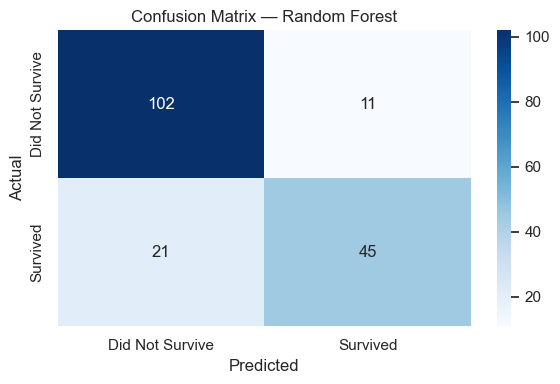

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=7)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
metrics_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
results.append(metrics_rf)
trained_models["Random Forest"] = rf

plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")


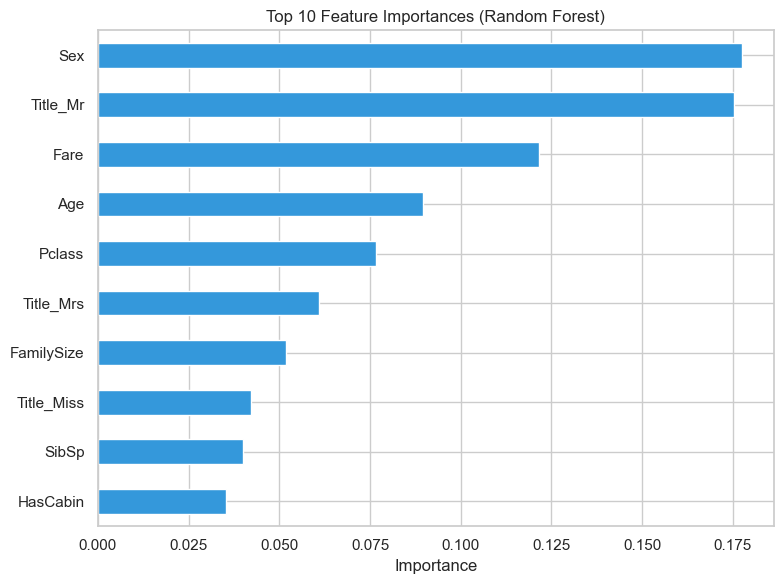

In [18]:
# Feature importance from Random Forest
feature_imp_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_imp_rf = feature_imp_rf.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp_rf.tail(10).plot(kind="barh", ax=ax, color="#3498db")
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## KNN


  K-Nearest Neighbors Results
  Accuracy:  0.8212
  Precision: 0.7656
  Recall:    0.7424
  F1 Score:  0.7538

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86       113
           1       0.77      0.74      0.75        66

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



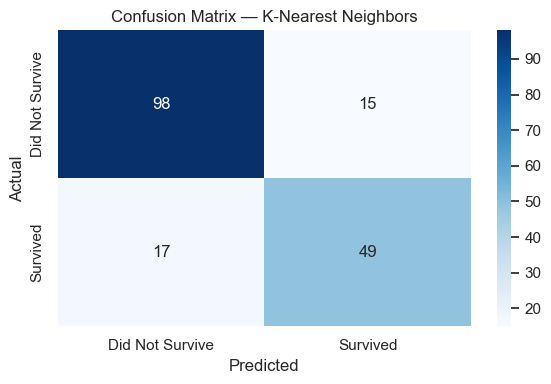

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
metrics_knn = evaluate_model(y_test, y_pred_knn, "K-Nearest Neighbors")
results.append(metrics_knn)
trained_models["K-Nearest Neighbors"] = knn

plot_confusion_matrix(y_test, y_pred_knn, "K-Nearest Neighbors")


In [21]:
from sklearn.model_selection import cross_val_score

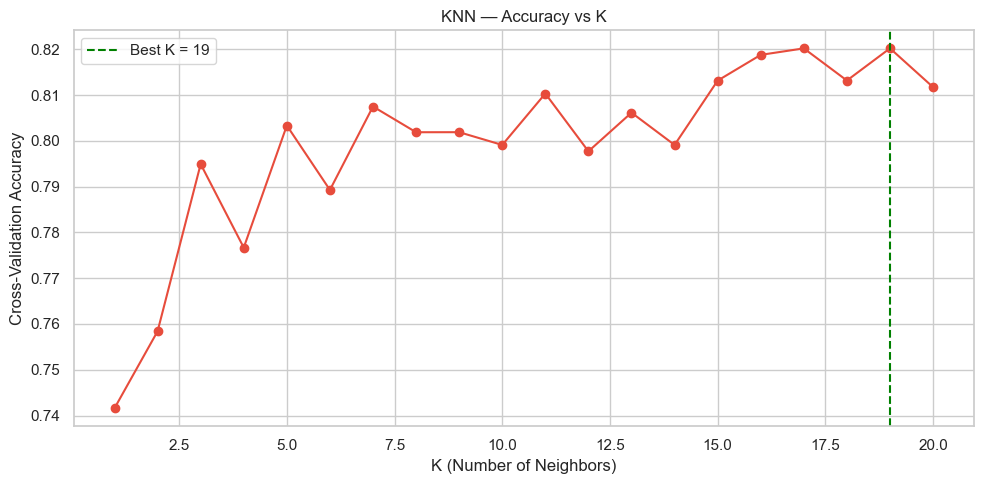

Best K: 19 with accuracy: 0.8202


In [22]:
# Find optimal K using cross-validation
k_range = range(1, 21)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy")
    k_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, marker="o", color="#e74c3c")
ax.set_title("KNN — Accuracy vs K")
ax.set_xlabel("K (Number of Neighbors)")
ax.set_ylabel("Cross-Validation Accuracy")
best_k = list(k_range)[np.argmax(k_scores)]
ax.axvline(x=best_k, color="green", linestyle="--", label=f"Best K = {best_k}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Best K: {best_k} with accuracy: {max(k_scores):.4f}")


## SVM


  SVM Results
  Accuracy:  0.8101
  Precision: 0.7667
  Recall:    0.6970
  F1 Score:  0.7302

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       113
           1       0.77      0.70      0.73        66

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



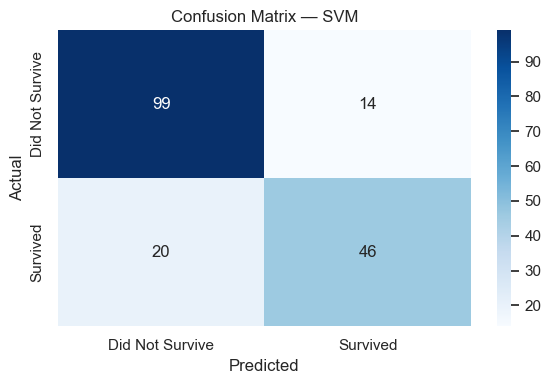

In [23]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
metrics_svm = evaluate_model(y_test, y_pred_svm, "SVM")
results.append(metrics_svm)
trained_models["SVM"] = svm

plot_confusion_matrix(y_test, y_pred_svm, "SVM")


## Gradient Boosting


  Gradient Boosting Results
  Accuracy:  0.8268
  Precision: 0.8070
  Recall:    0.6970
  F1 Score:  0.7480

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87       113
           1       0.81      0.70      0.75        66

    accuracy                           0.83       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179



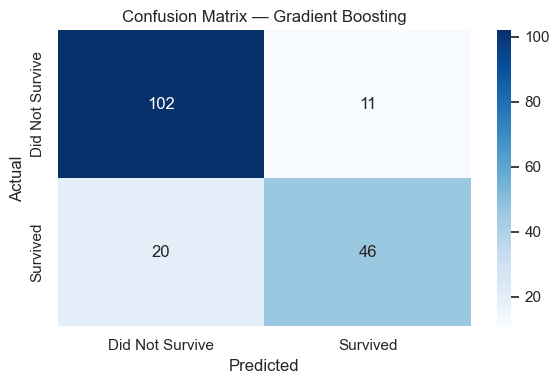

In [24]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
metrics_gb = evaluate_model(y_test, y_pred_gb, "Gradient Boosting")
results.append(metrics_gb)
trained_models["Gradient Boosting"] = gb

plot_confusion_matrix(y_test, y_pred_gb, "Gradient Boosting")


## Gaussian Naive Bayes


  Naive Bayes Results
  Accuracy:  0.7933
  Precision: 0.6933
  Recall:    0.7879
  F1 Score:  0.7376

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.80      0.83       113
           1       0.69      0.79      0.74        66

    accuracy                           0.79       179
   macro avg       0.78      0.79      0.78       179
weighted avg       0.80      0.79      0.80       179



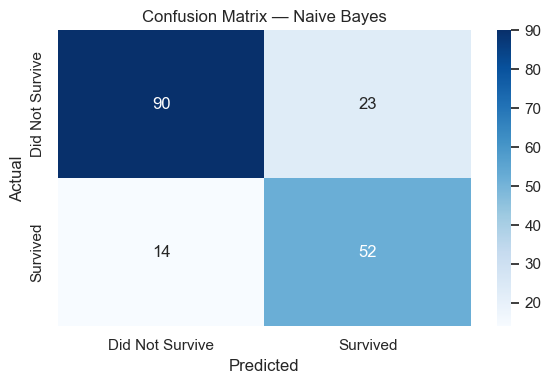

In [26]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
metrics_nb = evaluate_model(y_test, y_pred_nb, "Naive Bayes")
results.append(metrics_nb)
trained_models["Naive Bayes"] = nb

plot_confusion_matrix(y_test, y_pred_nb, "Naive Bayes")


# Model Comparison

In [27]:
# Compare all models
comparison_df = compare_models(results)
comparison_df.style.background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1 Score"])


,Model,Accuracy,Precision,Recall,F1 Score
0,K-Nearest Neighbors,0.821229,0.765625,0.742424,0.753846
1,Gradient Boosting,0.826816,0.807018,0.696970,0.747967
2,Decision Tree,0.810056,0.750000,0.727273,0.738462
3,Random Forest,0.821229,0.803571,0.681818,0.737705
4,Naive Bayes,0.793296,0.693333,0.787879,0.737589
5,Logistic Regression,0.810056,0.758065,0.712121,0.734375
6,SVM,0.810056,0.766667,0.696970,0.730159


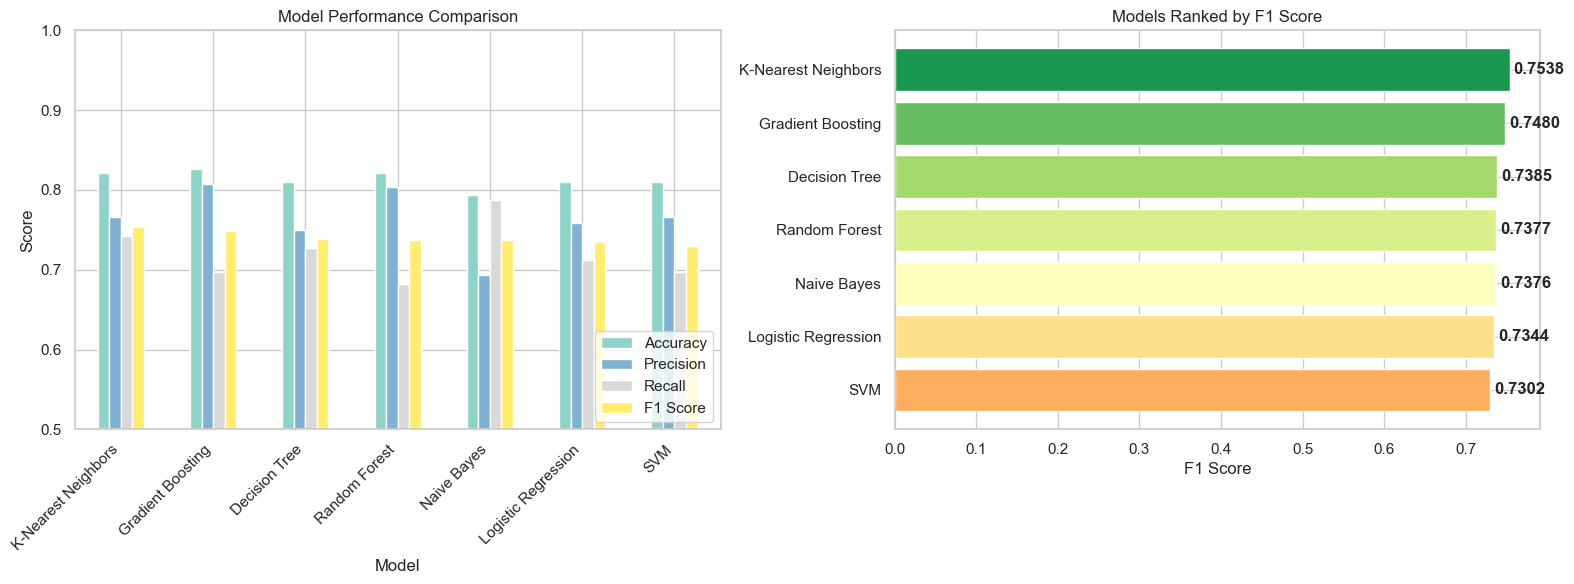

In [40]:
# Visualize model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of all metrics
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", ax=axes[0], colormap="Set3"
)
axes[0].set_title("Model Performance Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.5, 1.0)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].legend(loc="lower right")

# F1 Score ranking
sorted_df = comparison_df.sort_values("F1 Score", ascending=True)
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(sorted_df)))
axes[1].barh(sorted_df["Model"], sorted_df["F1 Score"], color=colors)
axes[1].set_title("Models Ranked by F1 Score")
axes[1].set_xlabel("F1 Score")
for i, v in enumerate(sorted_df["F1 Score"]):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()


In [39]:
# Cross-validation for all models (5-fold)
cv_results = {}

models_for_cv = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, max_depth=7),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=3),
    "Naive Bayes": GaussianNB(),
}

print("5-Fold Cross-Validation Results:")
print("=" * 55)
for name, model in models_for_cv.items():
    # Use scaled data for models that need it
    if name in ["Logistic Regression", "KNN", "SVM", "Naive Bayes"]:
        scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy")
    else:
        scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_results[name] = scores
    print(f"{name:25s} — Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")


5-Fold Cross-Validation Results:
Logistic Regression       — Mean: 0.8328 (+/- 0.0166)
Decision Tree             — Mean: 0.8258 (+/- 0.0385)
Random Forest             — Mean: 0.8412 (+/- 0.0258)
KNN                       — Mean: 0.8033 (+/- 0.0245)
SVM                       — Mean: 0.8342 (+/- 0.0291)
Gradient Boosting         — Mean: 0.8398 (+/- 0.0161)
Naive Bayes               — Mean: 0.7837 (+/- 0.0189)


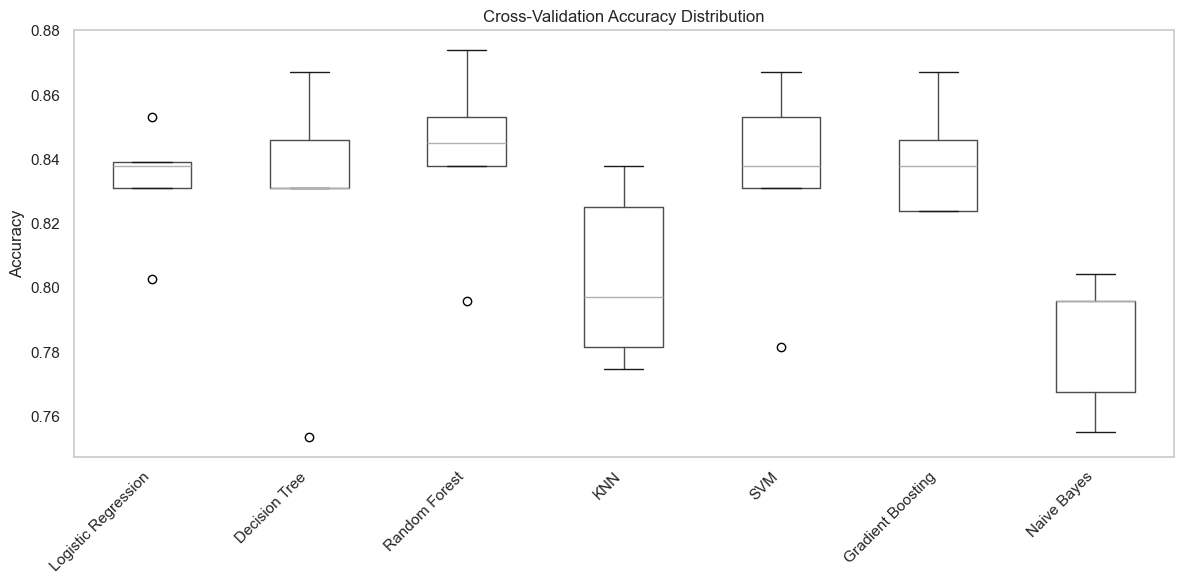

In [41]:
# Box plot of cross-validation scores
fig, ax = plt.subplots(figsize=(12, 6))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=False)
ax.set_title("Cross-Validation Accuracy Distribution")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()


## ROC Curve

<Figure size 1000x700 with 0 Axes>

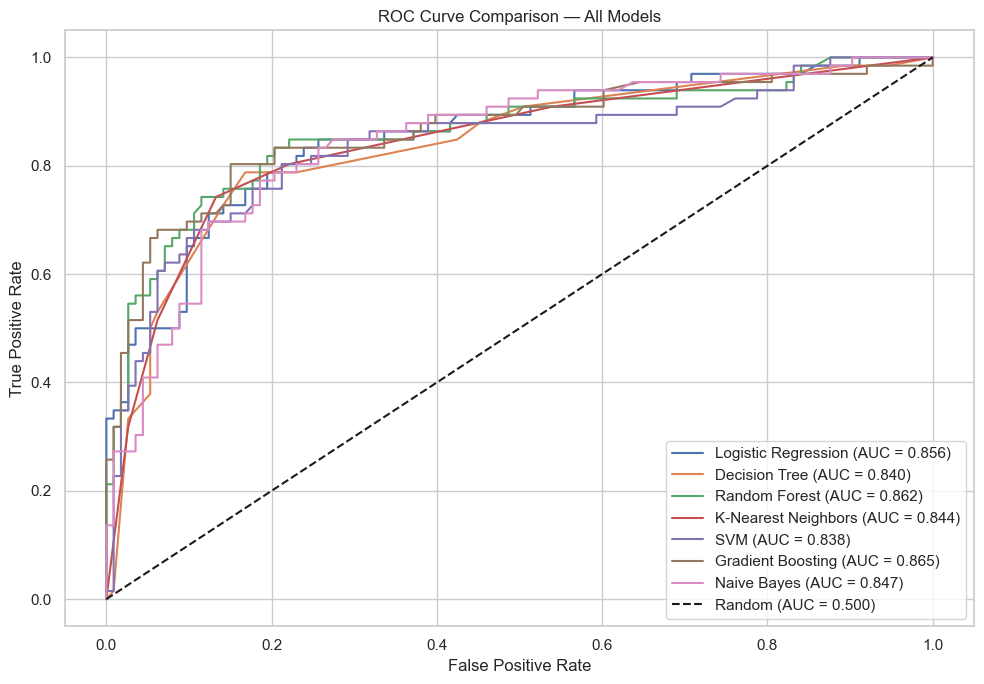

In [43]:
# Plot ROC curves for all models
# Note: KNN, SVM, LR, NB use scaled data; DT, RF, GB use unscaled
from sklearn.metrics import roc_curve,auc
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():
    # Choose the right test data
    if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM", "Naive Bayes"]:
        X_eval = X_test_scaled
    else:
        X_eval = X_test
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_eval)[:, 1]
    else:
        y_prob = model.decision_function(X_eval)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
